Ustalenia: rozdzielczość robocza na ten moment**128×128**, oficjalny podział **7007 / 1003 / 2005** (train / val / test) bez zmian.

Zawartość:
1. Balans klas i punkt odniesienia „zawsze NV”
2. Przykładowe obrazy i porównanie rozdzielczości
3. Analiza barw RGB (statystyki do normalizacji)
4. Jasność i kontrast
5. Jakość danych: duplikaty, przeciek między podziałami, artefakty
6. Rzut 2D (PCA, t-SNE)
7. Wnioski


In [ ]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.neighbors import NearestNeighbors
from medmnist import DermaMNIST

SIZE = 128
SEED = 42
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

CODES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
NAMES_PL = [
    "rogowacenie słoneczne / rak śródnaskórkowy",
    "rak podstawnokomórkowy",
    "łagodne zmiany rogowaciejące",
    "włókniak skóry (dermatofibroma)",
    "czerniak",
    "znamiona melanocytowe",
    "zmiany naczyniowe",
]

CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
RGB_COLORS = {"R": "#e34948", "G": "#008300", "B": "#2a78d6"}
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 100, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

def show_images(imgs, titles=None, ncols=8, size=1.5, suptitle=None):
    n = len(imgs); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * (1.22 if titles else 1.0)))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel(): ax.axis("off")
    for i, im in enumerate(imgs):
        ax = axes.ravel()[i]; ax.imshow(im)
        if titles: ax.set_title(titles[i], fontsize=8, fontweight="normal", loc="center", color=INK2)
    if suptitle: fig.suptitle(suptitle, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(h_pad=1.6)
    return fig

## 0. Wczytanie danych

In [2]:
def load(split, size=SIZE):
    fname = "dermamnist.npz" if size == 28 else f"dermamnist_{size}.npz"
    ds = DermaMNIST(split=split, size=size, download=not (DATA_DIR / fname).exists(), root=str(DATA_DIR))
    return ds.imgs, ds.labels.ravel().astype(int)

X, y = {}, {}
for s in ["train", "val", "test"]:
    X[s], y[s] = load(s)
    print(f"{s:5s}  obrazy {X[s].shape} {X[s].dtype}  zakres [{X[s].min()}, {X[s].max()}]  etykiety {y[s].shape}")
Xtr, ytr = X["train"], y["train"]

train  obrazy (7007, 128, 128, 3) uint8  zakres [0, 255]  etykiety (7007,)
val    obrazy (1003, 128, 128, 3) uint8  zakres [0, 255]  etykiety (1003,)
test   obrazy (2005, 128, 128, 3) uint8  zakres [0, 255]  etykiety (2005,)


## 1. Balans klas

Liczność i udział każdej klasy w każdym podziale oraz sprawdzenie, czy podział jest stratyfikowany (czy udziały klas są takie same w train / val / test).

In [3]:
counts = pd.DataFrame({s: np.bincount(y[s], minlength=7) for s in y}, index=CODES)
share = (counts / counts.sum() * 100).round(2)
tab = pd.concat([counts, share.add_suffix(" %")], axis=1)
tab.insert(0, "klasa", NAMES_PL)
tab.loc["razem"] = ["—", *counts.sum().tolist(), *share.sum().round(0).tolist()]
print("Stosunek najliczniejszej do najrzadszej klasy (train): "
      f"{counts['train'].max() / counts['train'].min():.1f} : 1")
tab

Stosunek najliczniejszej do najrzadszej klasy (train): 58.7 : 1


,klasa,train,val,test,train %,val %,test %
akiec,rogowacenie słoneczne / rak śródnaskórkowy,228,33,66,3.25,3.29,3.29
bcc,rak podstawnokomórkowy,359,52,103,5.12,5.18,5.14
bkl,łagodne zmiany rogowaciejące,769,110,220,10.97,10.97,10.97
df,włókniak skóry (dermatofibroma),80,12,23,1.14,1.20,1.15
mel,czerniak,779,111,223,11.12,11.07,11.12
nv,znamiona melanocytowe,4693,671,1341,66.98,66.90,66.88
vasc,zmiany naczyniowe,99,14,29,1.41,1.40,1.45
razem,—,7007,1003,2005,100.00,100.00,100.00


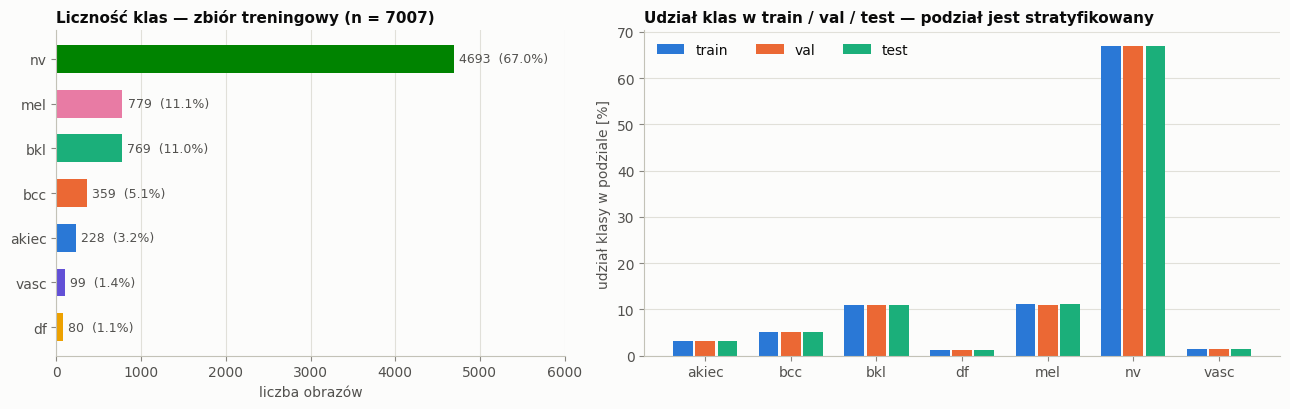

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})

order = np.argsort(counts["train"].values)
ax1.barh(np.array(CODES)[order], counts["train"].values[order],
         color=np.array(CLASS_COLORS)[order], height=0.62)
for i, k in enumerate(order):
    ax1.text(counts["train"].iloc[k] + 60, i, f"{counts['train'].iloc[k]}  ({share['train'].iloc[k]:.1f}%)",
             va="center", fontsize=9, color=INK2)
ax1.set_xlim(0, counts["train"].max() * 1.28)
ax1.set_xlabel("liczba obrazów"); ax1.grid(axis="y", visible=False)
ax1.set_title("Liczność klas — zbiór treningowy (n = 7007)")

w = 0.26
for j, s in enumerate(["train", "val", "test"]):
    ax2.bar(np.arange(7) + (j - 1) * w, share[s].values, width=w - 0.03, color=SPLIT_COLORS[s], label=s)
ax2.set_xticks(np.arange(7)); ax2.set_xticklabels(CODES)
ax2.set_ylabel("udział klasy w podziale [%]"); ax2.grid(axis="x", visible=False)
ax2.legend(frameon=False, ncol=3, loc="upper left")
ax2.set_title("Udział klas w train / val / test — podział jest stratyfikowany")
fig.tight_layout(); save(fig, "01_balans_klas"); plt.show()

### Punkt odniesienia: klasyfikator „zawsze NV”

Model, który dla każdego obrazu zwraca klasę większościową. Pokazuje, dlaczego samo accuracy jest tu mylące.

In [5]:
major = int(np.bincount(ytr).argmax())
rows = []
for s in ["val", "test"]:
    pred = np.full_like(y[s], major)
    rows.append({
        "podział": s,
        "accuracy": accuracy_score(y[s], pred),
        "balanced accuracy (macro recall)": balanced_accuracy_score(y[s], pred),
        "macro-F1": f1_score(y[s], pred, average="macro", zero_division=0),
        "recall czerniaka (mel)": float((pred[y[s] == 4] == 4).mean()),
    })
print(f"Klasa większościowa: {CODES[major]} ({NAMES_PL[major]})")
pd.DataFrame(rows).set_index("podział").round(3)

Klasa większościowa: nv (znamiona melanocytowe)


,accuracy,balanced accuracy (macro recall),macro-F1,recall czerniaka (mel)
podział,,,,
val,0.669,0.143,0.115,0.0
test,0.669,0.143,0.115,0.0


### Wagi klas (do późniejszej kompensacji niezbalansowania)

Wagi odwrotnie proporcjonalne do liczności (`n / (K · n_k)`), np. do ważonej funkcji straty.

In [6]:
n_k = counts["train"].values
weights = n_k.sum() / (len(n_k) * n_k)
pd.DataFrame({"n_train": n_k, "waga": weights.round(3)}, index=CODES)

,n_train,waga
akiec,228,4.390
bcc,359,2.788
bkl,769,1.302
df,80,12.512
mel,779,1.285
nv,4693,0.213
vasc,99,10.111


## 2. Przykładowe obrazy

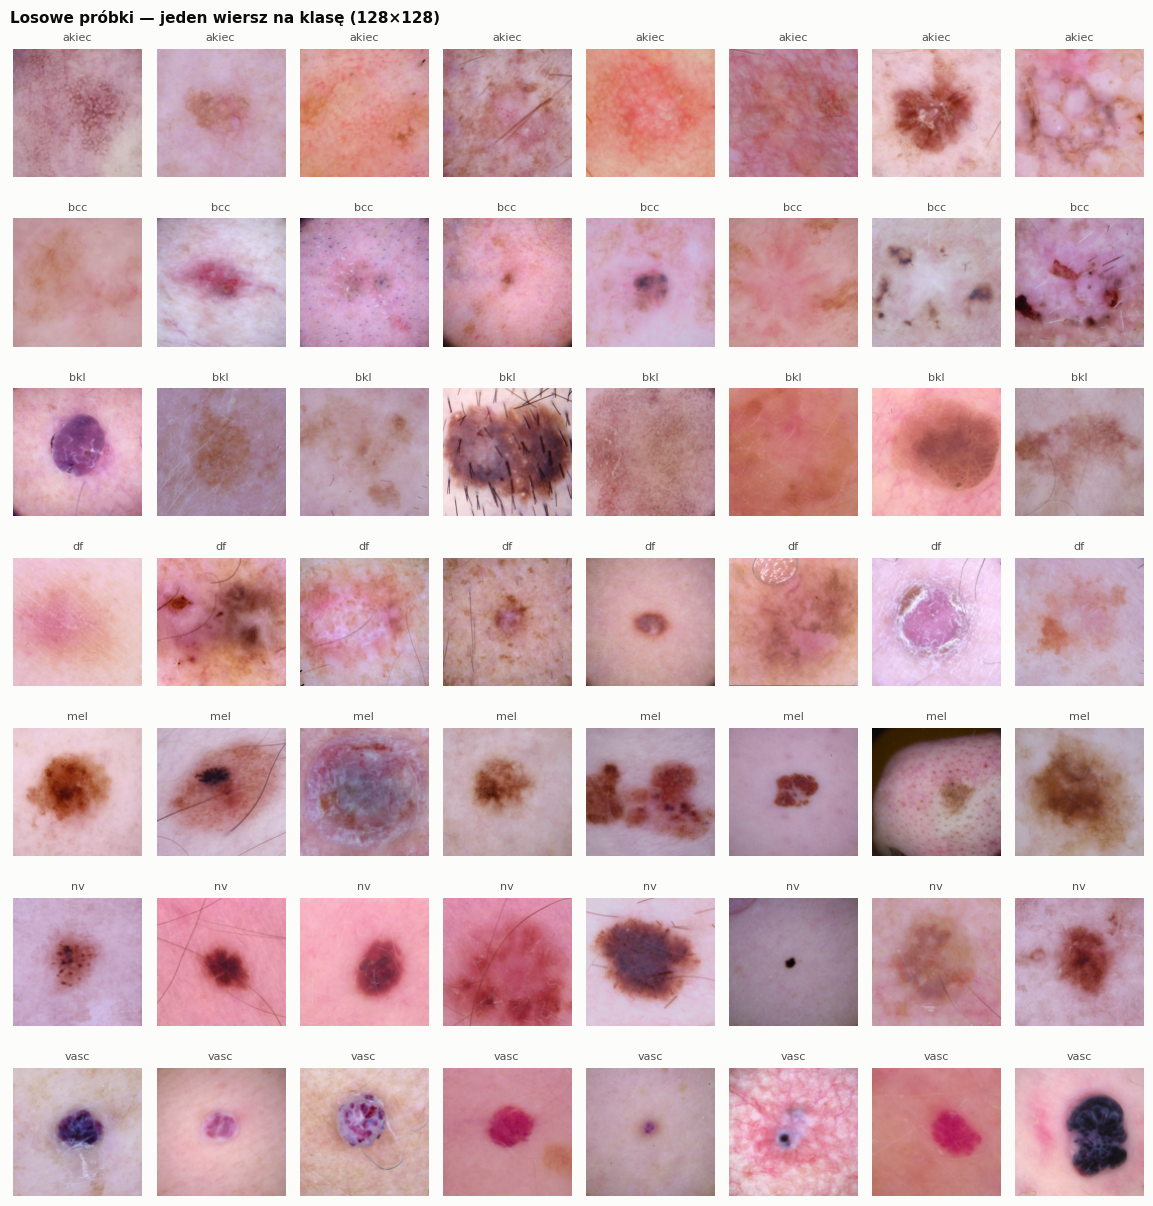

In [7]:
N_PER = 8
imgs, titles = [], []
for k in range(7):
    idx = rng.choice(np.where(ytr == k)[0], N_PER, replace=False)
    imgs += list(Xtr[idx]); titles += [CODES[k]] * N_PER
fig = show_images(imgs, titles, ncols=N_PER, size=1.45, suptitle="Losowe próbki — jeden wiersz na klasę (128×128)")
save(fig, "02_przykladowe_obrazy"); plt.show()

### Porównanie rozdzielczości 28 / 64 / 128 / 224

Te same obrazy (zbiór walidacyjny) w czterech wersjach udostępnianych przez MedMNIST. Wersje 28, 64 i 224 pobierają się przy pierwszym uruchomieniu (224 to większy plik); jeśli pobranie się nie uda, dana kolumna jest pomijana.

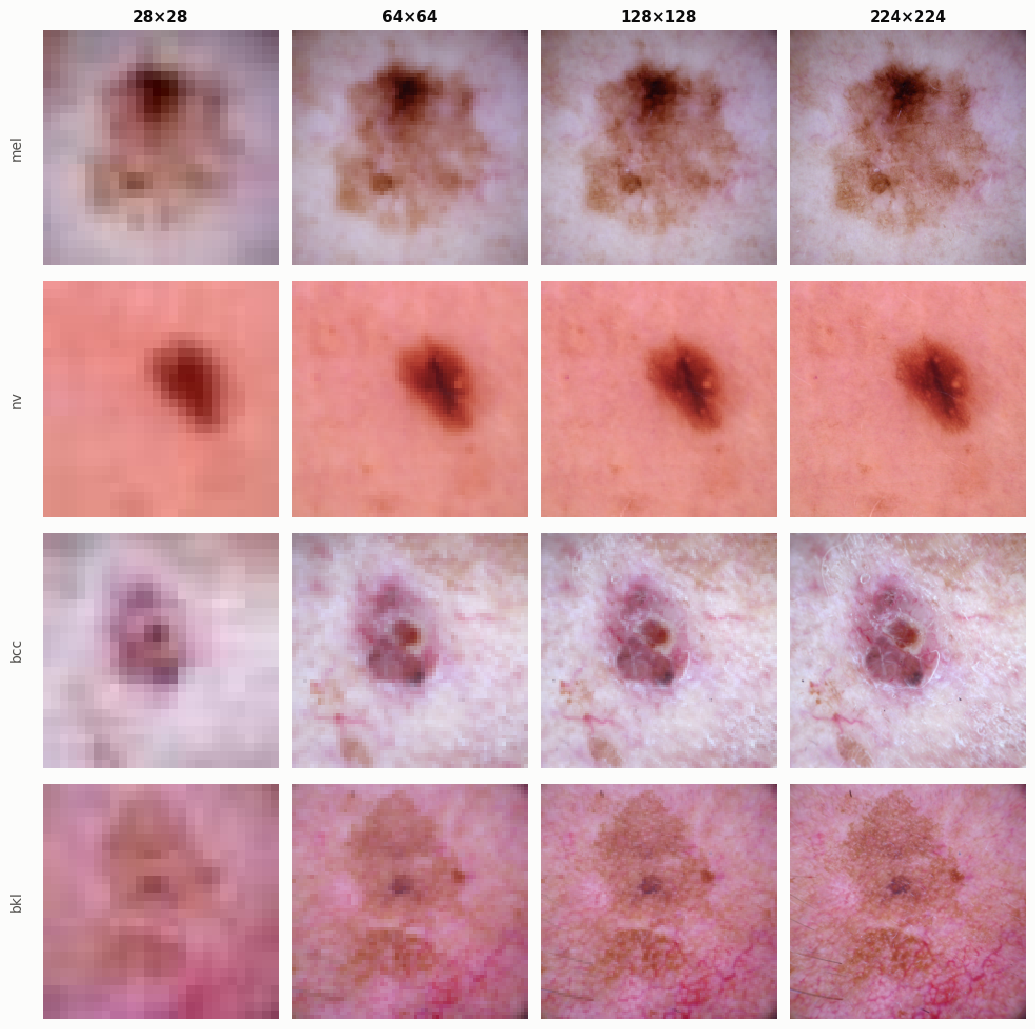

In [8]:
pick = [int(np.where(y["val"] == k)[0][0]) for k in [4, 5, 1, 2]]   # mel, nv, bcc, bkl
res_imgs = {}
for r in [28, 64, 128, 224]:
    try:
        res_imgs[r] = X["val"][pick] if r == SIZE else load("val", r)[0][pick]
    except Exception as e:
        print(f"Pominięto {r}×{r}: {e}")

fig, axes = plt.subplots(len(pick), len(res_imgs), figsize=(2.6 * len(res_imgs), 2.6 * len(pick)))
for j, (r, arr) in enumerate(res_imgs.items()):
    for i in range(len(pick)):
        ax = axes[i, j]; ax.imshow(arr[i], interpolation="nearest"); ax.axis("off")
        if i == 0: ax.set_title(f"{r}×{r}", loc="center")
        if j == 0: ax.text(-0.08, 0.5, CODES[y["val"][pick[i]]], transform=ax.transAxes,
                           rotation=90, va="center", ha="right", color=INK2)
fig.tight_layout(); save(fig, "03_rozdzielczosci"); plt.show()

## 3. Analiza barw RGB

Średnia i odchylenie standardowe kanałów (na zbiorze treningowym, w skali 0–1) — to są wartości do normalizacji wejścia sieci. Dalej histogramy intensywności kanałów ogółem i w podziale na klasy.

In [9]:
# Histogramy intensywności per kanał i per klasa (dokładne, na wszystkich pikselach train)
hist = np.zeros((7, 3, 256), dtype=np.int64)
for k in range(7):
    Xk = Xtr[ytr == k]
    for c in range(3):
        hist[k, c] = np.bincount(Xk[..., c].ravel(), minlength=256)

levels = np.arange(256) / 255.0
def mean_std(h):
    p = h / h.sum(); m = (p * levels).sum(); return m, np.sqrt((p * (levels - m) ** 2).sum())

h_all = hist.sum(axis=0)
MEAN, STD = zip(*[mean_std(h_all[c]) for c in range(3)])
print("Statystyki do normalizacji (train, skala 0-1):")
print("  mean =", [round(float(v), 4) for v in MEAN])
print("  std  =", [round(float(v), 4) for v in STD])
print("Dla porównania ImageNet: mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225]")

rgb_tab = pd.DataFrame(
    {f"{ch} {stat}": [mean_std(hist[k, c])[i] for k in range(7)]
     for c, ch in enumerate("RGB") for i, stat in enumerate(["średnia", "std"])}, index=CODES).round(3)
rgb_tab

Statystyki do normalizacji (train, skala 0-1):
  mean = [0.7632, 0.538, 0.5615]
  std  = [0.1364, 0.1581, 0.1762]
Dla porównania ImageNet: mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225]


,R średnia,R std,G średnia,G std,B średnia,B std
akiec,0.786,0.091,0.587,0.117,0.611,0.134
bcc,0.777,0.091,0.614,0.116,0.641,0.128
bkl,0.707,0.120,0.549,0.129,0.577,0.148
df,0.782,0.100,0.583,0.117,0.618,0.133
mel,0.699,0.147,0.535,0.171,0.560,0.194
nv,0.780,0.137,0.527,0.163,0.548,0.181
vasc,0.776,0.143,0.573,0.169,0.634,0.152


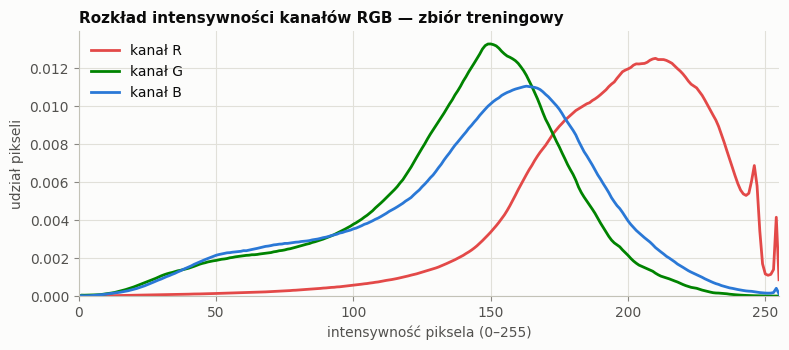

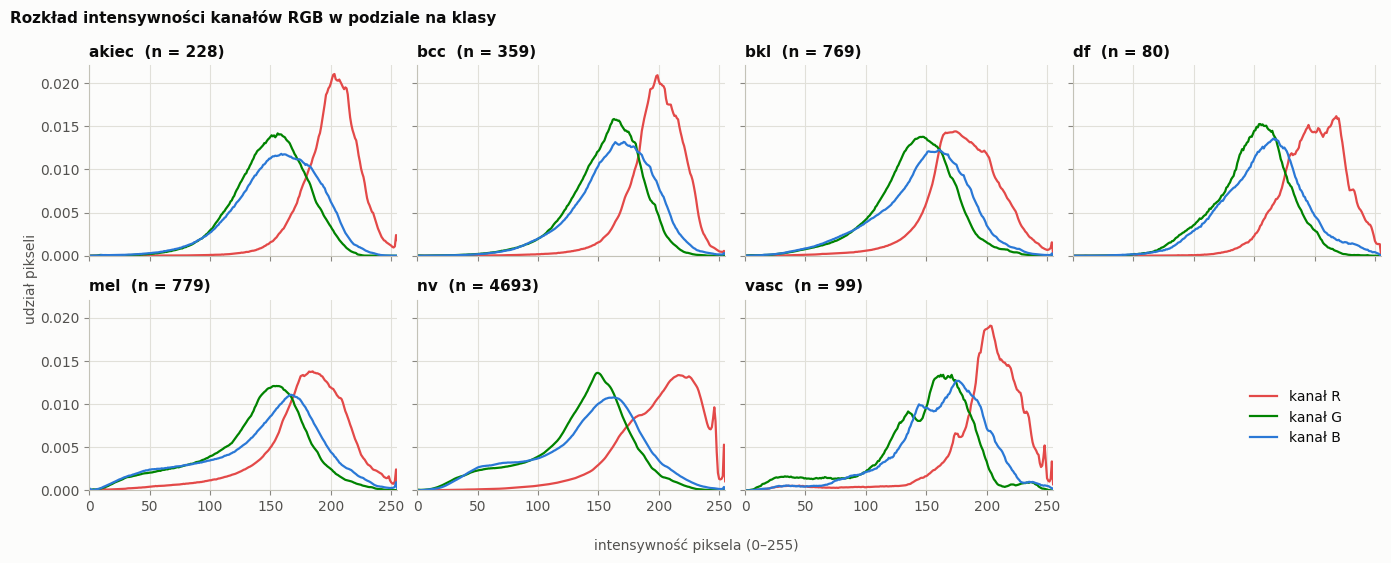

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for c, ch in enumerate("RGB"):
    ax.plot(np.arange(256), h_all[c] / h_all[c].sum(), color=RGB_COLORS[ch], lw=2, label=f"kanał {ch}")
ax.set_xlabel("intensywność piksela (0–255)"); ax.set_ylabel("udział pikseli")
ax.set_xlim(0, 255); ax.set_ylim(0); ax.legend(frameon=False)
ax.set_title("Rozkład intensywności kanałów RGB — zbiór treningowy")
fig.tight_layout(); save(fig, "04_histogram_rgb"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 5.6), sharex=True, sharey=True)
for k, ax in enumerate(axes.ravel()[:7]):
    for c, ch in enumerate("RGB"):
        ax.plot(np.arange(256), hist[k, c] / hist[k, c].sum(), color=RGB_COLORS[ch], lw=1.6,
                label=f"kanał {ch}" if k == 0 else None)
    ax.set_title(f"{CODES[k]}  (n = {int((ytr == k).sum())})"); ax.set_xlim(0, 255); ax.set_ylim(0)
axes.ravel()[7].axis("off")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower right", bbox_to_anchor=(0.97, 0.18), frameon=False)
fig.supxlabel("intensywność piksela (0–255)", color=INK2, fontsize=10)
fig.supylabel("udział pikseli", color=INK2, fontsize=10)
fig.suptitle("Rozkład intensywności kanałów RGB w podziale na klasy", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); save(fig, "05_histogram_rgb_klasy"); plt.show()

### Średni obraz każdej klasy

Uśrednienie wszystkich obrazów klasy piksel po pikselu — pokazuje typowe położenie i barwę zmiany oraz to, czy zmiana jest wycentrowana.

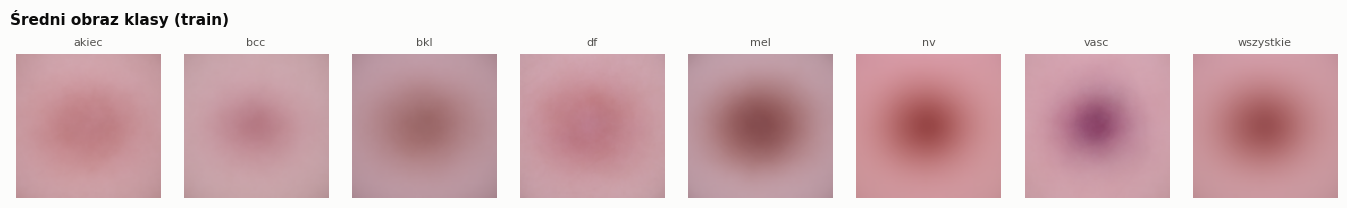

In [11]:
means = [Xtr[ytr == k].mean(axis=0).astype(np.uint8) for k in range(7)] + [Xtr.mean(axis=0).astype(np.uint8)]
fig = show_images(means, CODES + ["wszystkie"], ncols=8, size=1.7, suptitle="Średni obraz klasy (train)")
save(fig, "06_sredni_obraz_klas"); plt.show()

## 4. Jasność i kontrast

Dla każdego obrazu: jasność = średnia luminancja (0.299R + 0.587G + 0.114B), kontrast = odchylenie standardowe luminancji. Sprawdzamy, czy klasy różnią się samą ekspozycją — to cecha, której model mógłby się „nauczyć na skróty”.

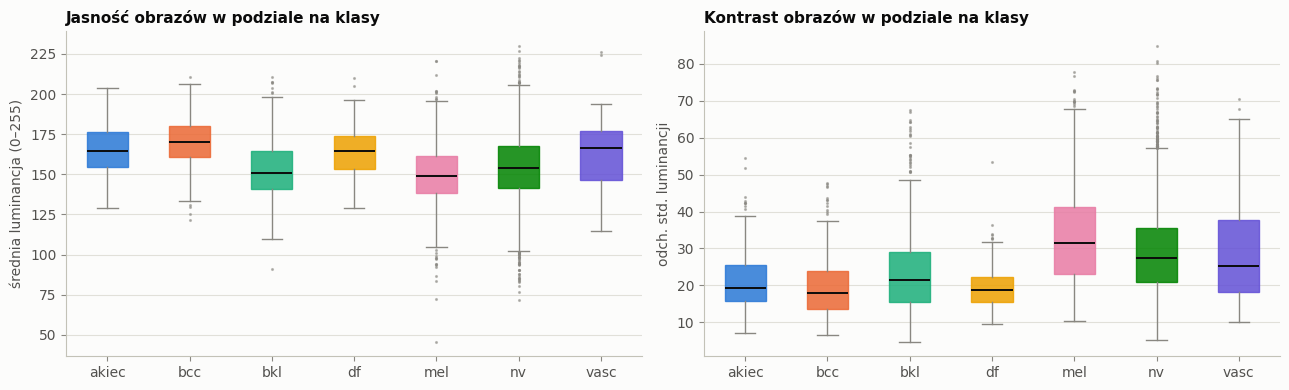

,jasność (mediana),kontrast (mediana)
akiec,164.7,19.3
bcc,170.4,18.0
bkl,150.9,21.5
df,164.8,18.6
mel,148.8,31.4
nv,154.3,27.4
vasc,166.6,25.2


In [12]:
LUM = np.array([0.299, 0.587, 0.114], dtype=np.float32)
def to_gray(arr, chunk=1000):
    out = np.empty(arr.shape[:3], dtype=np.uint8)
    for i in range(0, len(arr), chunk):
        out[i:i + chunk] = (arr[i:i + chunk].astype(np.float32) @ LUM).round().astype(np.uint8)
    return out

G = {s: to_gray(X[s]) for s in X}
Gtr = G["train"]
bright = Gtr.reshape(len(Gtr), -1).mean(axis=1)
contrast = Gtr.reshape(len(Gtr), -1).std(axis=1)

def class_box(ax, values, title, ylabel):
    bp = ax.boxplot([values[ytr == k] for k in range(7)], patch_artist=True, widths=0.5,
                    medianprops=dict(color=INK, lw=1.4), flierprops=dict(marker=".", ms=2.5, mec=MUTED, mfc=MUTED, alpha=0.5),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, col in zip(bp["boxes"], CLASS_COLORS):
        patch.set_facecolor(col); patch.set_edgecolor(col); patch.set_alpha(0.85)
    ax.set_xticks(range(1, 8)); ax.set_xticklabels(CODES); ax.grid(axis="x", visible=False)
    ax.set_title(title); ax.set_ylabel(ylabel)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
class_box(ax1, bright, "Jasność obrazów w podziale na klasy", "średnia luminancja (0–255)")
class_box(ax2, contrast, "Kontrast obrazów w podziale na klasy", "odch. std. luminancji")
fig.tight_layout(); save(fig, "07_jasnosc_kontrast"); plt.show()

pd.DataFrame({"jasność (mediana)": [np.median(bright[ytr == k]) for k in range(7)],
              "kontrast (mediana)": [np.median(contrast[ytr == k]) for k in range(7)]}, index=CODES).round(1)

## 5. Jakość danych

### 5.1 Dokładne duplikaty i przeciek między podziałami

Skrót MD5 z pikseli każdego obrazu. Identyczny skrót w dwóch różnych podziałach oznaczałby przeciek danych.

In [13]:
recs = [{"split": s, "idx": i, "label": int(y[s][i]), "md5": hashlib.md5(X[s][i].tobytes()).hexdigest()}
        for s in X for i in range(len(X[s]))]
H = pd.DataFrame(recs)
grp = H.groupby("md5")
dup = grp.filter(lambda g: len(g) > 1)
cross = grp.filter(lambda g: g["split"].nunique() > 1)
print(f"Obrazów łącznie: {len(H)}, unikalnych: {H['md5'].nunique()}")
print(f"Obrazy należące do grup dokładnych duplikatów: {len(dup)} (grup: {dup['md5'].nunique()})")
print(f"  w tym grupy obecne w więcej niż jednym podziale: {cross['md5'].nunique()}")
if len(dup):
    print(f"  grupy z niezgodną etykietą: {int((dup.groupby('md5')['label'].nunique() > 1).sum())}")

Obrazów łącznie: 10015, unikalnych: 10013
Obrazy należące do grup dokładnych duplikatów: 4 (grup: 2)
  w tym grupy obecne w więcej niż jednym podziale: 0
  grupy z niezgodną etykietą: 0


### 5.2 Bardzo podobne obrazy między train a val/test

HAM10000 zawiera po kilka zdjęć tej samej zmiany skórnej, a MedMNIST nie udostępnia identyfikatorów zmian. Przybliżenie: każdy obraz zmniejszamy do 16×16 w skali szarości i dla każdego obrazu z val/test szukamy najbliższego obrazu w train (RMSE w skali 0–255). Bardzo mała odległość = prawie na pewno to samo zdjęcie; inne ujęcia tej samej zmiany (obrót, przesunięcie, zoom) tą metodą **nie** zostaną wykryte.

val: mediana RMSE do najbliższego obrazu w train = 13.0; RMSE < 3: 0, < 5: 8, < 6: 15  (na 1003)
test: mediana RMSE do najbliższego obrazu w train = 13.3; RMSE < 3: 5, < 5: 12, < 6: 17  (na 2005)
train→train: mediana = 13.2; RMSE < 3: 8, < 5: 35, < 6: 63  (na 7007)


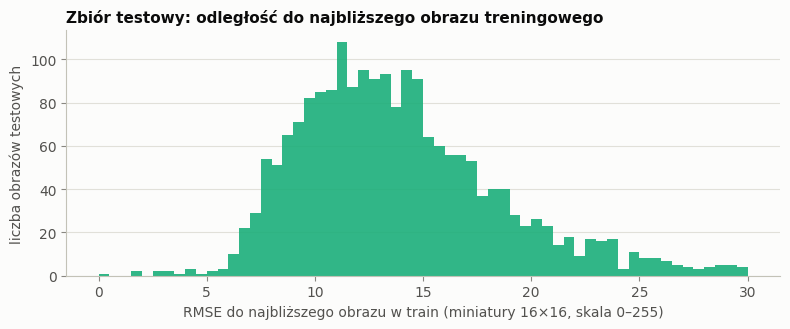

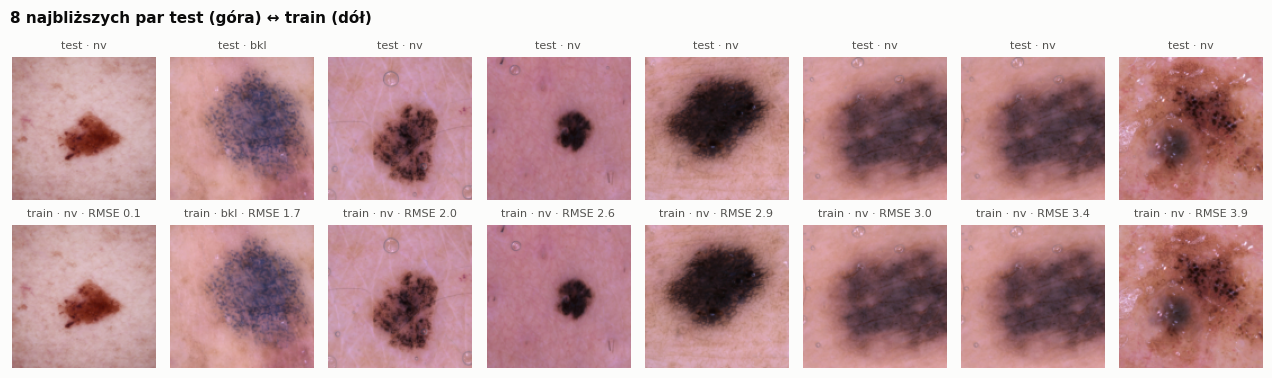

In [14]:
def thumb(g, f=8):
    n, h, w = g.shape
    return g.reshape(n, h // f, f, w // f, f).mean(axis=(2, 4)).reshape(n, -1).astype(np.float32)

T = {s: thumb(G[s]) for s in G}
nn = NearestNeighbors(n_neighbors=1).fit(T["train"])
near = {}
for s in ["val", "test"]:
    d, j = nn.kneighbors(T[s])
    near[s] = pd.DataFrame({"idx": np.arange(len(T[s])), "train_idx": j.ravel(),
                            "rmse": d.ravel() / np.sqrt(T[s].shape[1])})
    near[s]["ta sama etykieta"] = y[s] == ytr[near[s]["train_idx"]]

# Skala odniesienia: odległość do najbliższego sąsiada wewnątrz train (z pominięciem samego siebie)
d_in = NearestNeighbors(n_neighbors=2).fit(T["train"]).kneighbors(T["train"])[0][:, 1] / np.sqrt(T["train"].shape[1])

for s in near:
    q = near[s]["rmse"]
    print(f"{s}: mediana RMSE do najbliższego obrazu w train = {q.median():.1f}; "
          f"RMSE < 3: {(q < 3).sum()}, < 5: {(q < 5).sum()}, < 6: {(q < 6).sum()}  (na {len(q)})")
print(f"train→train: mediana = {np.median(d_in):.1f}; RMSE < 3: {(d_in < 3).sum()}, < 5: {(d_in < 5).sum()}, < 6: {(d_in < 6).sum()}  (na {len(d_in)})")

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 30, 61)
ax.hist(near["test"]["rmse"], bins=bins, color=SPLIT_COLORS["test"], alpha=0.9)
ax.set_xlabel("RMSE do najbliższego obrazu w train (miniatury 16×16, skala 0–255)"); ax.set_ylabel("liczba obrazów testowych")
ax.set_title("Zbiór testowy: odległość do najbliższego obrazu treningowego"); ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "08_najblizszy_sasiad"); plt.show()

top = near["test"].nsmallest(8, "rmse")
pairs, titles = [], []
for _, r in top.iterrows():
    pairs.append(X["test"][int(r.idx)]); titles.append(f"test · {CODES[y['test'][int(r.idx)]]}")
for _, r in top.iterrows():
    pairs.append(Xtr[int(r.train_idx)]); titles.append(f"train · {CODES[ytr[int(r.train_idx)]]} · RMSE {r.rmse:.1f}")
fig = show_images(pairs, titles, ncols=8, size=1.6, suptitle="8 najbliższych par test (góra) ↔ train (dół)")
save(fig, "09_najblizsze_pary"); plt.show()

### 5.3 Obrazy skrajnie ciemne i jasne

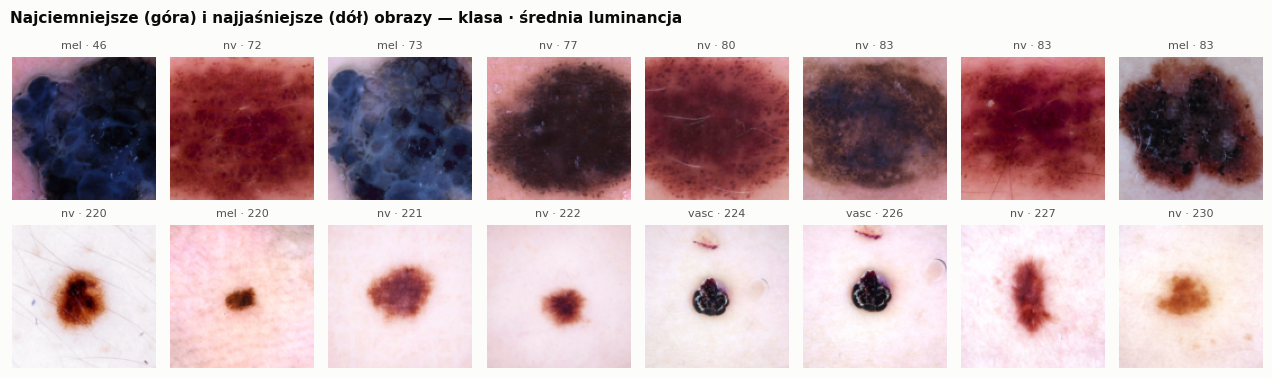

In [15]:
o = np.argsort(bright)
fig = show_images(list(Xtr[o[:8]]) + list(Xtr[o[-8:]]),
                  [f"{CODES[ytr[i]]} · {bright[i]:.0f}" for i in list(o[:8]) + list(o[-8:])],
                  ncols=8, size=1.6, suptitle="Najciemniejsze (góra) i najjaśniejsze (dół) obrazy — klasa · średnia luminancja")
save(fig, "10_skrajna_jasnosc"); plt.show()

### 5.4 Artefakty: ciemne rogi (winieta) i włosy

- **Ciemne rogi / winieta**: średnia luminancja czterech narożników 12×12 w porównaniu ze środkiem obrazu.
- **Włosy**: prosty wskaźnik morfologiczny (*black top-hat*: domknięcie minus obraz) — udział pikseli tworzących cienkie, ciemne struktury. To heurystyka do znalezienia przykładów, nie dokładny detektor.

Jeśli częstość artefaktu różni się między klasami, model może nauczyć się artefaktu zamiast zmiany — warto to potem sprawdzić na mapach Grad-CAM.

Ogółem: ciemny narożnik 1.5% obrazów, włosy (heurystyka) 4.9%


,ciemny narożnik [% obrazów],włosy (heurystyka) [% obrazów],śr. luminancja narożników
akiec,0.9,11.8,163.3
bcc,0.8,6.7,166.4
bkl,3.3,7.2,153.7
df,1.2,3.8,169.2
mel,3.2,4.5,159.5
nv,1.1,4.1,166.3
vasc,0.0,3.0,172.5


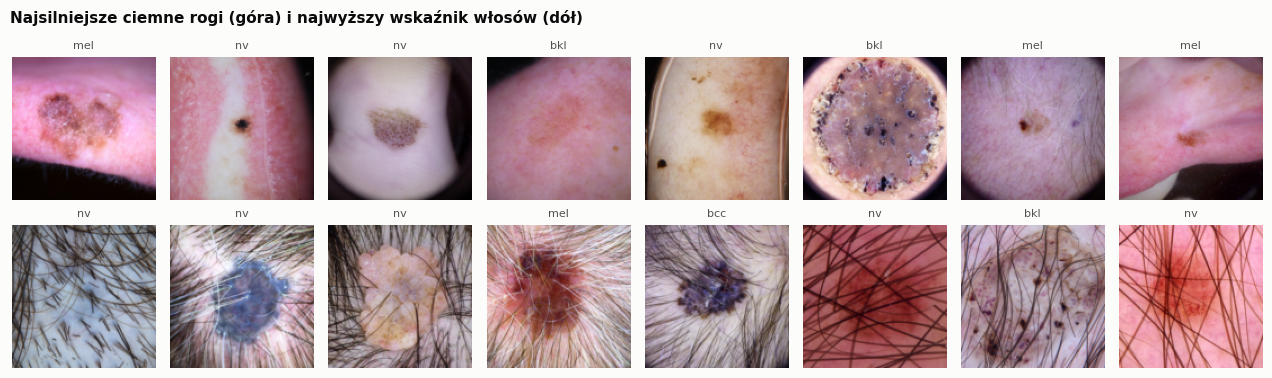

In [16]:
c = 12
corners = np.stack([Gtr[:, :c, :c], Gtr[:, :c, -c:], Gtr[:, -c:, :c], Gtr[:, -c:, -c:]], axis=1).reshape(len(Gtr), 4, -1).mean(axis=2)
corner_mean = corners.mean(axis=1)
corner_min = corners.min(axis=1)
dark_corner = corner_min < 60          # co najmniej jeden wyraźnie ciemny narożnik

def hair_score(g, size=7, thr=25):
    bh = ndimage.grey_closing(g, size=(size, size)).astype(np.int16) - g
    return float((bh > thr).mean())
hair = np.array([hair_score(g) for g in Gtr])
hairy = hair > 0.05

art = pd.DataFrame({
    "ciemny narożnik [% obrazów]": [100 * dark_corner[ytr == k].mean() for k in range(7)],
    "włosy (heurystyka) [% obrazów]": [100 * hairy[ytr == k].mean() for k in range(7)],
    "śr. luminancja narożników": [corner_mean[ytr == k].mean() for k in range(7)],
}, index=CODES).round(1)
print(f"Ogółem: ciemny narożnik {100 * dark_corner.mean():.1f}% obrazów, włosy (heurystyka) {100 * hairy.mean():.1f}%")
display(art)

i1 = np.argsort(corner_min)[:8]; i2 = np.argsort(-hair)[:8]
fig = show_images(list(Xtr[i1]) + list(Xtr[i2]), [CODES[ytr[i]] for i in list(i1) + list(i2)],
                  ncols=8, size=1.6, suptitle="Najsilniejsze ciemne rogi (góra) i najwyższy wskaźnik włosów (dół)")
save(fig, "11_artefakty"); plt.show()

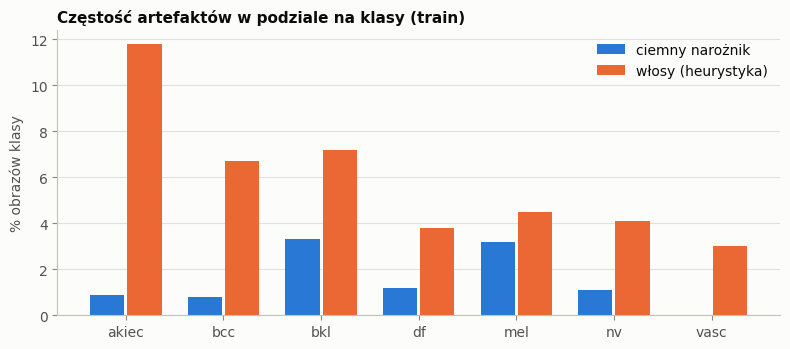

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.38
ax.bar(np.arange(7) - w / 2, art.iloc[:, 0], width=w - 0.03, color="#2a78d6", label="ciemny narożnik")
ax.bar(np.arange(7) + w / 2, art.iloc[:, 1], width=w - 0.03, color="#eb6834", label="włosy (heurystyka)")
ax.set_xticks(np.arange(7)); ax.set_xticklabels(CODES); ax.set_ylabel("% obrazów klasy"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False); ax.set_title("Częstość artefaktów w podziale na klasy (train)")
fig.tight_layout(); save(fig, "12_artefakty_klasy"); plt.show()

## 6. Rzut 2D: PCA i t-SNE

Podpróba zbioru treningowego (maks. 400 obrazów na klasę), obrazy zmniejszone do 32×32 RGB, PCA do 50 składowych, potem t-SNE. Pokazuje, na ile klasy da się rozdzielić na podstawie samych surowych pikseli.

Wariancja wyjaśniona: PC1 34.2%, PC2 15.6%, pierwsze 10 składowych 79.3%, 50 składowych 93.1%


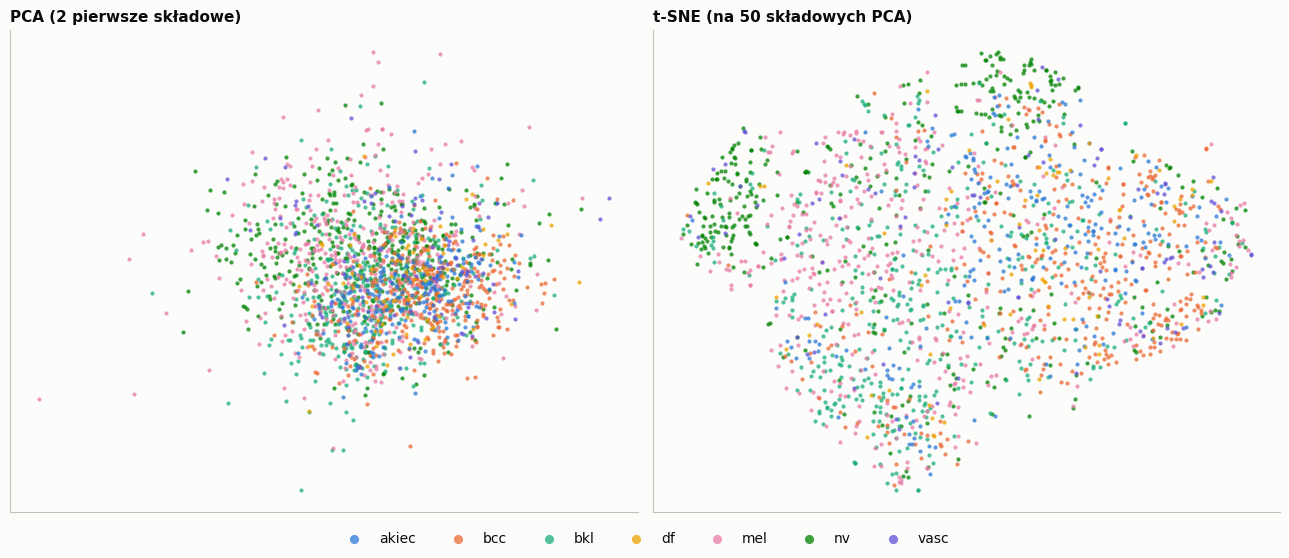

In [18]:
sub = np.concatenate([rng.choice(np.where(ytr == k)[0], min(400, int((ytr == k).sum())), replace=False) for k in range(7)])
Xs = Xtr[sub].reshape(len(sub), 32, 4, 32, 4, 3).mean(axis=(2, 4)).reshape(len(sub), -1) / 255.0
ys = ytr[sub]
pca = PCA(n_components=50, random_state=SEED).fit(Xs)
Z = pca.transform(Xs)
ev = pca.explained_variance_ratio_
print(f"Wariancja wyjaśniona: PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%}, pierwsze 10 składowych {ev[:10].sum():.1%}, 50 składowych {ev.sum():.1%}")
E = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, P, title in [(axes[0], Z[:, :2], "PCA (2 pierwsze składowe)"), (axes[1], E, "t-SNE (na 50 składowych PCA)")]:
    for k in [5, 2, 4, 1, 0, 6, 3]:                      # najliczniejsze pod spodem
        m = ys == k
        ax.scatter(P[m, 0], P[m, 1], s=9, color=CLASS_COLORS[k], alpha=0.75, linewidths=0, label=CODES[k])
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
h, l = axes[0].get_legend_handles_labels()
o = [l.index(cde) for cde in CODES]
fig.legend([h[i] for i in o], [l[i] for i in o], loc="lower center", ncol=7, frameon=False, markerscale=2.2)
fig.tight_layout(rect=(0, 0.05, 1, 1)); save(fig, "13_pca_tsne"); plt.show()